In [ ]:
import cv2
import pytesseract
import numpy as np
import matplotlib.pyplot as plt
import os

# Membaca gambar dari folder yang sama dengan notebook
print("Silakan simpan gambar ijazah di folder yang sama dengan notebook.")

# Membuat dictionary global untuk menyimpan data setiap gambar di setiap tahapan
data_ijazah = {}

# Mencari semua file gambar di folder
ekstensi_gambar = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

daftar_gambar = [
    filename for filename in os.listdir('.')
    if filename.lower().endswith(ekstensi_gambar)
]

# Menyimpan nama file ke dictionary
for filename in daftar_gambar:
    data_ijazah[filename] = {}

print(f"\nBerhasil memuat {len(data_ijazah)} file gambar.")
print("Daftar gambar:", list(data_ijazah.keys()))
print("Lanjut ke Sel berikutnya.")


Silakan simpan gambar ijazah di folder yang sama dengan notebook.

Berhasil memuat 9 file gambar.
Daftar gambar: ['01_HighQuality_Enhanced.jpg', '02_LowContrast.jpg', '03_Blurred.jpg', '04_HighNoise.jpg', '05_LowResolution_Upsampled.jpg', '06_Faded_Underexposed.jpg', '07_ColorShift_WarmTint.jpg', '08_JPEGCompression_Artifacts.jpg', '09_CombinedDegradation.jpg']
Lanjut ke Sel berikutnya.


In [20]:
# SEL 2: PIPELINE PRE-PROCESSING

for filename, data in data_ijazah.items():

    img = cv2.imread(filename)

    if img is None:
        print(f"Gagal memuat gambar: {filename}")
        continue

    # Tidak melakukan rotasi
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Image enhancement menggunakan CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_gray = clahe.apply(gray)

    # Simpan hasil ke dictionary
    data['original'] = img
    data['gray'] = gray
    data['enhanced_gray'] = enhanced_gray

    print(f"Preprocessing selesai: {filename}")

print("Semua gambar selesai diproses.")

Preprocessing selesai: 01_HighQuality_Enhanced.jpg
Preprocessing selesai: 02_LowContrast.jpg
Preprocessing selesai: 03_Blurred.jpg
Preprocessing selesai: 04_HighNoise.jpg
Preprocessing selesai: 05_LowResolution_Upsampled.jpg
Preprocessing selesai: 06_Faded_Underexposed.jpg
Preprocessing selesai: 07_ColorShift_WarmTint.jpg
Preprocessing selesai: 08_JPEGCompression_Artifacts.jpg
Preprocessing selesai: 09_CombinedDegradation.jpg
Semua gambar selesai diproses.


In [21]:
# SEL 3: PEMOTONGAN AREA (ROI)

for filename, data in data_ijazah.items():
    img = cv2.imread(filename)
    if img is None:
        print(f"Gagal memuat {filename}")
        continue

    # 1. Rotasi 90 derajat searah jarum jam (Portrait)
    img_rotated = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

    # Grayscale & CLAHE Enhancement
    gray = cv2.cvtColor(img_rotated, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced_gray = clahe.apply(gray)
    data['enhanced_gray'] = enhanced_gray

    H, W = enhanced_gray.shape

    # 2. Potong area lebih luas agar teks & TTD utuh tidak terpotong:

    # Area Nomor Ijazah (Diperlebar dari Y: 85% - 99% dan X: 60% - 99%)
    data['roi_nomor'] = enhanced_gray[int(H * 0.89) : int(H * 0.98), int(W * 0.02) : int(W * 0.30)]

    # Area Tanda Tangan Rektor (Diperlebar dari Y: 70% - 98% dan X: 50% - 99%)
    data['roi_ttd'] = enhanced_gray[int(H * 0.65) : int(H * 0.85), int(W * 0.10) : int(W * 0.43)]

print("Pemotongan Area (ROI) Selesai.")

Pemotongan Area (ROI) Selesai.


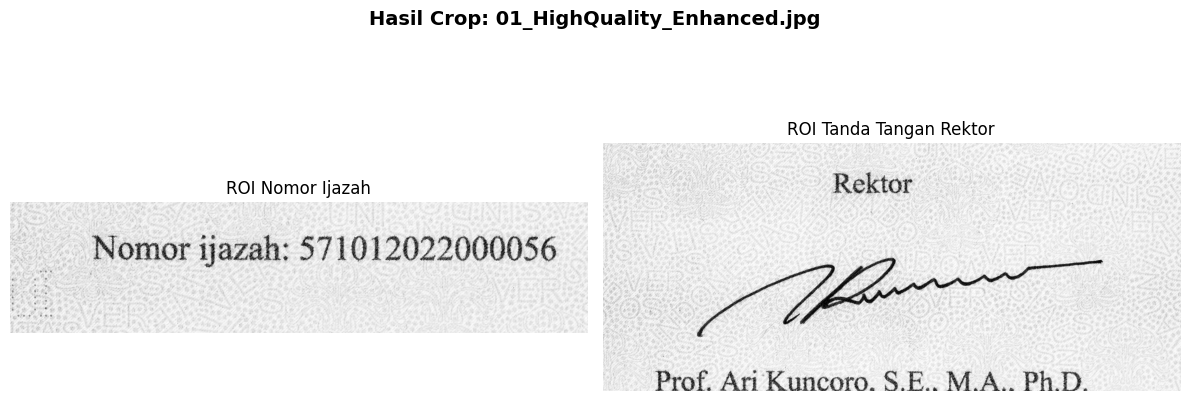

--------------------------------------------------


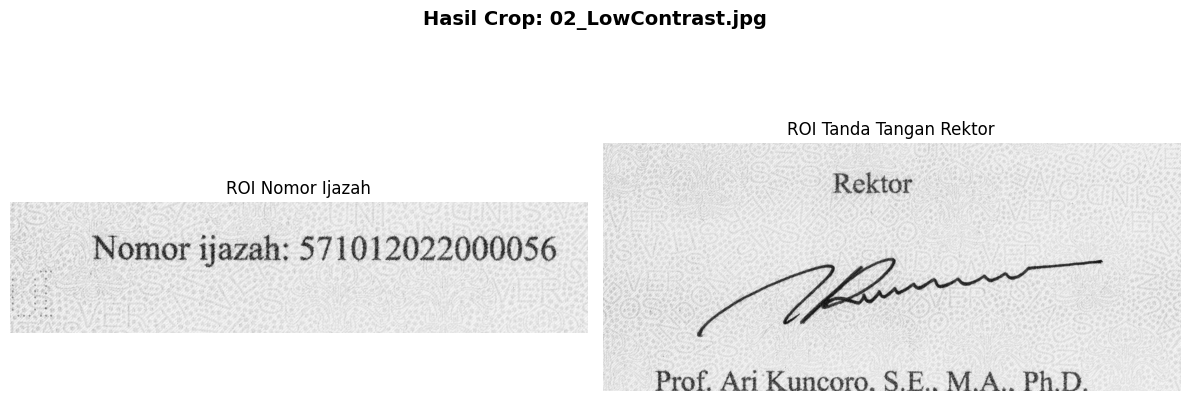

--------------------------------------------------


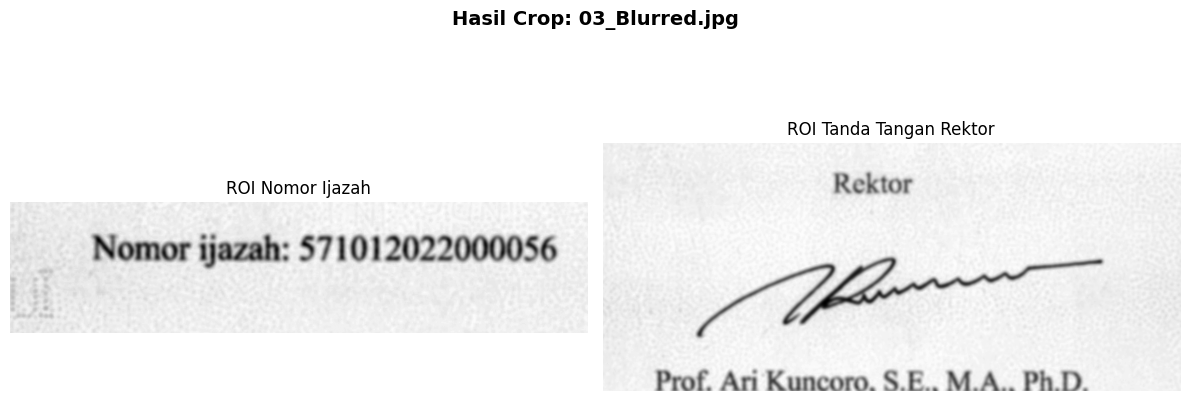

--------------------------------------------------


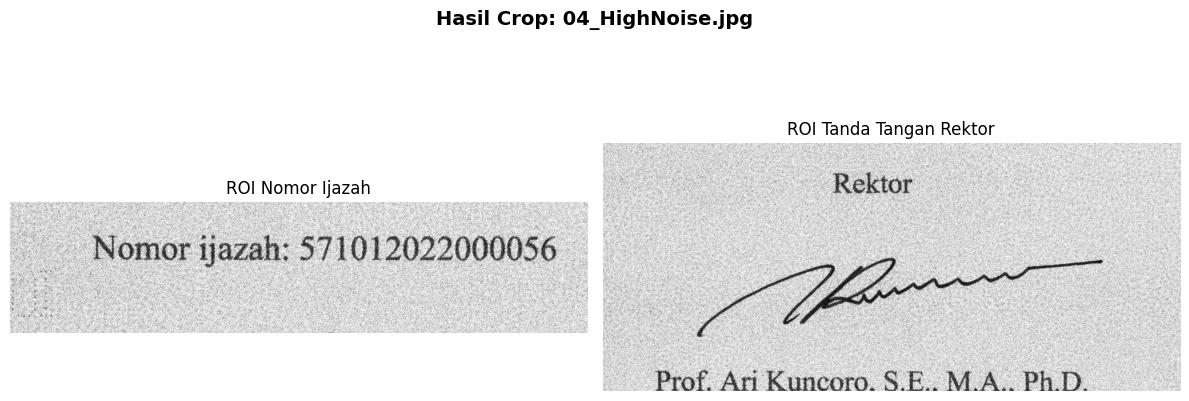

--------------------------------------------------


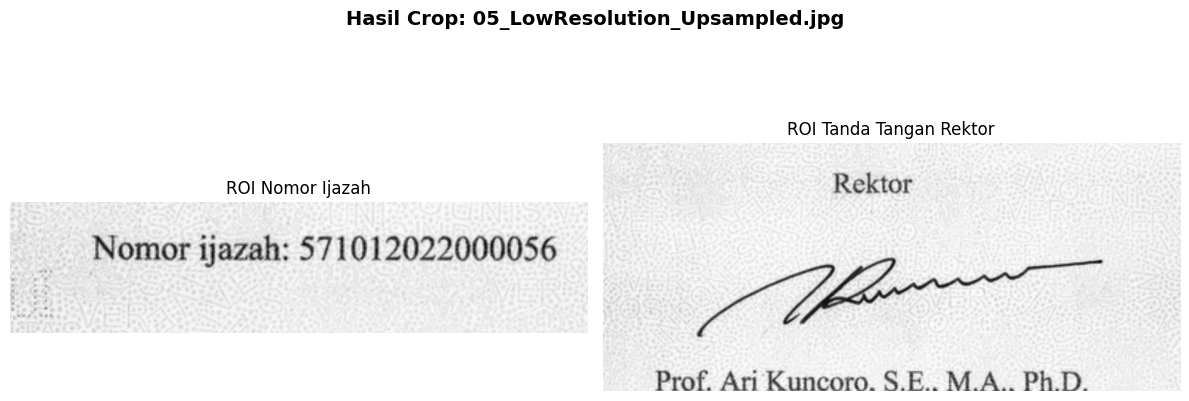

--------------------------------------------------


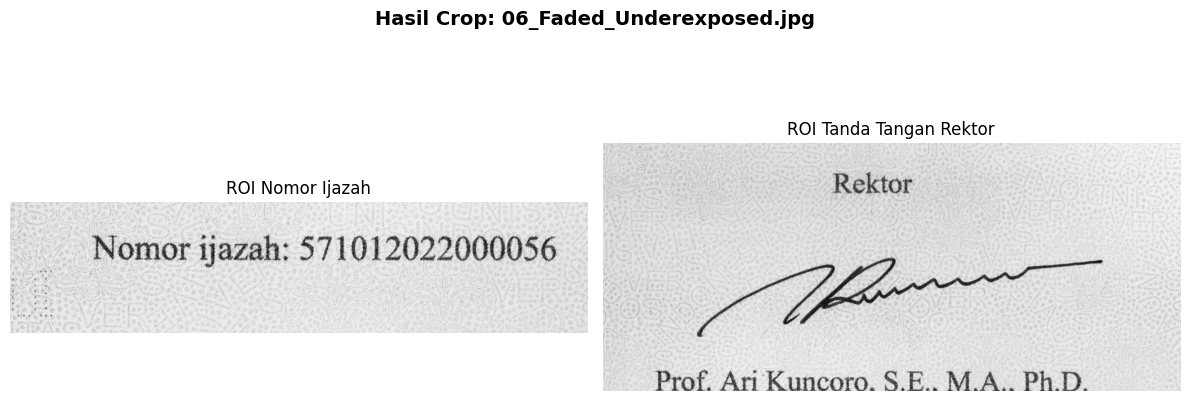

--------------------------------------------------


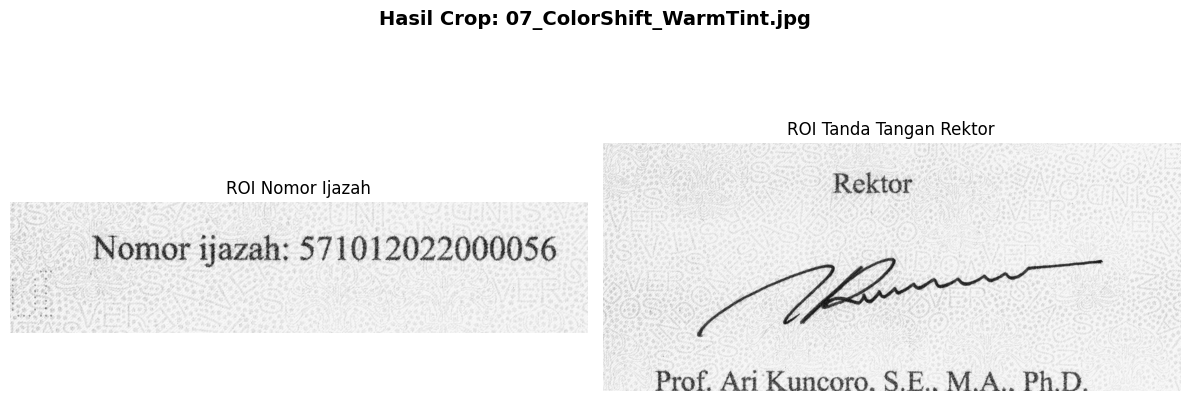

--------------------------------------------------


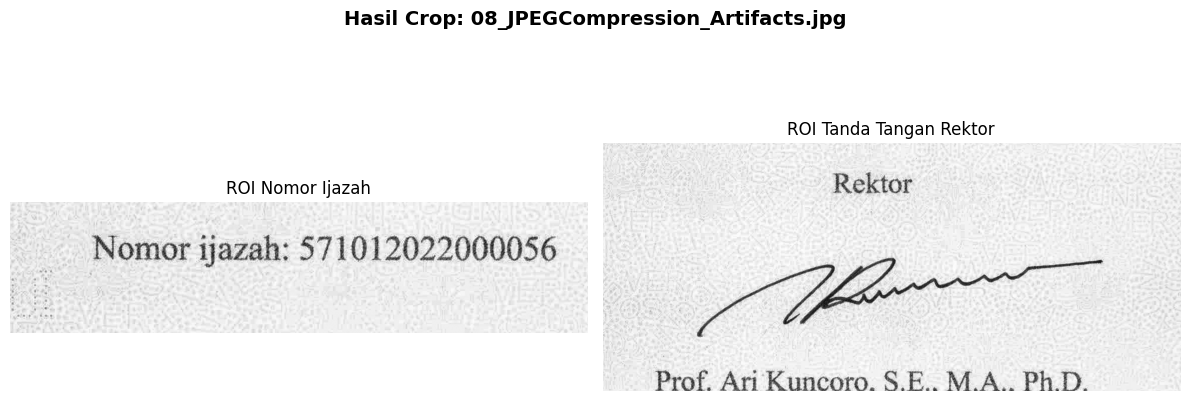

--------------------------------------------------


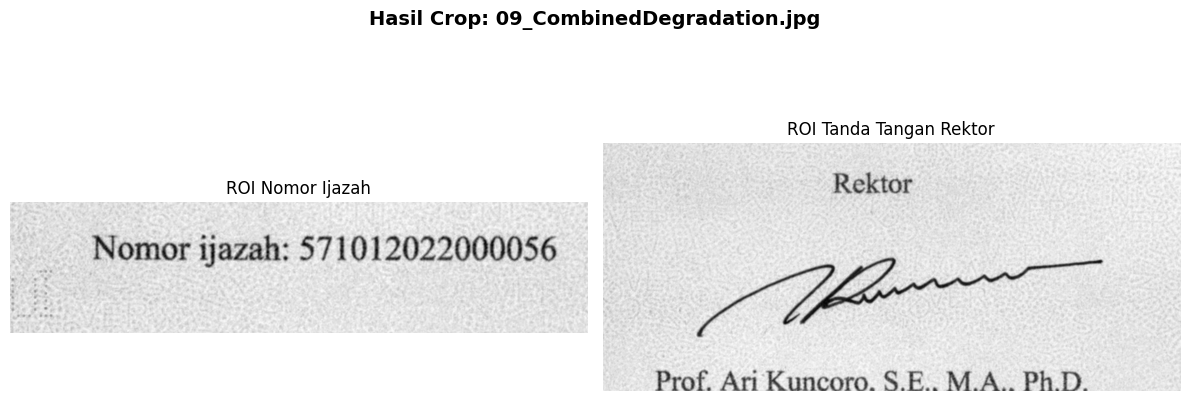

--------------------------------------------------


In [23]:
# SEL 4: VISUALISASI HASIL CROP

import matplotlib.pyplot as plt

for filename, data in data_ijazah.items():

    if 'roi_nomor' not in data or 'roi_ttd' not in data:
        continue

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    fig.suptitle(
        f"Hasil Crop: {filename}",
        fontsize=14,
        fontweight='bold'
    )

    # Crop nomor ijazah
    ax[0].imshow(
        data['roi_nomor'],
        cmap='gray'
    )
    ax[0].set_title("ROI Nomor Ijazah")
    ax[0].axis('off')

    # Crop tanda tangan
    ax[1].imshow(
        data['roi_ttd'],
        cmap='gray'
    )
    ax[1].set_title("ROI Tanda Tangan Rektor")
    ax[1].axis('off')

    plt.tight_layout()
    plt.show()

    print("-" * 50)

In [29]:
# SEL 5: EKSTRAKSI NOMOR (OCR)

# ==========================================
# FUNGSI OCR NOMOR IJAZAH
# ==========================================

import re
import cv2
import pytesseract

def baca_nomor_ijazah(roi):
    # Memperbesar ROI
    img = cv2.resize(
        roi, None,
        fx=3, fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Mengurangi noise
    img = cv2.GaussianBlur(img, (3, 3), 0)

    # Thresholding Otsu
    _, binary = cv2.threshold(
        img, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # OCR
    config = (
        "--oem 3 --psm 6 "
        "-c tessedit_char_whitelist=0123456789"
    )

    teks = pytesseract.image_to_string(
        binary,
        config=config
    )

    # Ambil rangkaian angka saja
    angka = re.findall(r'\d+', teks)

    # Pilih rangkaian angka terpanjang
    if angka:
        nomor = max(angka, key=len)
    else:
        nomor = "Tidak terbaca"

    return nomor

In [30]:
# ==========================================
# PROSES OCR SEMUA GAMBAR
# ==========================================

for filename, data in data_ijazah.items():

    if 'roi_nomor' not in data:
        data['nomor_ijazah_text'] = "Area nomor tidak tersedia"
        continue

    nomor = baca_nomor_ijazah(data['roi_nomor'])

    data['nomor_ijazah_text'] = nomor

    print(f"{filename}: {nomor}")

01_HighQuality_Enhanced.jpg: 571012022000056
02_LowContrast.jpg: 571012022000056
03_Blurred.jpg: 571012022000056
04_HighNoise.jpg: Tidak terbaca
05_LowResolution_Upsampled.jpg: 571012022000056
06_Faded_Underexposed.jpg: 571012022000056
07_ColorShift_WarmTint.jpg: 571012022000056
08_JPEGCompression_Artifacts.jpg: 571012022000056
09_CombinedDegradation.jpg: 571012022000056


In [31]:
# SEL 6: DETEKSI TANDA TANGAN REKTOR

for filename, data in data_ijazah.items():
    if 'roi_ttd' not in data: continue

    # Otsu Thresholding (Inverse) agar tinta jadi putih
    _, thresh_ttd = cv2.threshold(data['roi_ttd'], 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Morfologi untuk menyambung piksel tinta yang terputus
    kernel = np.ones((5,5), np.uint8)
    morph_ttd = cv2.morphologyEx(thresh_ttd, cv2.MORPH_CLOSE, kernel)

    # Perhitungan kepadatan piksel
    total_pixels = morph_ttd.shape[0] * morph_ttd.shape[1]
    white_pixels = cv2.countNonZero(morph_ttd)
    ink_density = (white_pixels / total_pixels) * 100

    # Simpan hasil
    data['morph_ttd'] = morph_ttd
    data['ink_density'] = ink_density
    data['status_ttd'] = "PRESENT" if ink_density > 1.5 else "ABSENT"

print("Deteksi keberadaan Tanda Tangan selesai.")

Deteksi keberadaan Tanda Tangan selesai.


In [38]:
# SEL 7: CETAK OUTPUT SESUAI FORMAT SOAL

for filename, data in data_ijazah.items():

    nomor = data.get(
        'nomor_ijazah_text',
        'Tidak terbaca'
    )

    status_ttd = data.get(
        'status_ttd',
        'Belum terdeteksi'
    )

    print(f"\n[{filename}]")
    print("Input:")
    print(filename)

    print("\nOutput:")
    print(f"Nomor Ijazah : {nomor}")
    print(f"Tanda Tangan : {status_ttd}")

    print("-" * 40)

print(f"\nTotal gambar: {len(data_ijazah)}")


[01_HighQuality_Enhanced.jpg]
Input:
01_HighQuality_Enhanced.jpg

Output:
Nomor Ijazah : 571012022000056
Tanda Tangan : PRESENT
----------------------------------------

[02_LowContrast.jpg]
Input:
02_LowContrast.jpg

Output:
Nomor Ijazah : 571012022000056
Tanda Tangan : PRESENT
----------------------------------------

[03_Blurred.jpg]
Input:
03_Blurred.jpg

Output:
Nomor Ijazah : 571012022000056
Tanda Tangan : PRESENT
----------------------------------------

[04_HighNoise.jpg]
Input:
04_HighNoise.jpg

Output:
Nomor Ijazah : Tidak terbaca
Tanda Tangan : PRESENT
----------------------------------------

[05_LowResolution_Upsampled.jpg]
Input:
05_LowResolution_Upsampled.jpg

Output:
Nomor Ijazah : 571012022000056
Tanda Tangan : PRESENT
----------------------------------------

[06_Faded_Underexposed.jpg]
Input:
06_Faded_Underexposed.jpg

Output:
Nomor Ijazah : 571012022000056
Tanda Tangan : PRESENT
----------------------------------------

[07_ColorShift_WarmTint.jpg]
Input:
07_ColorS

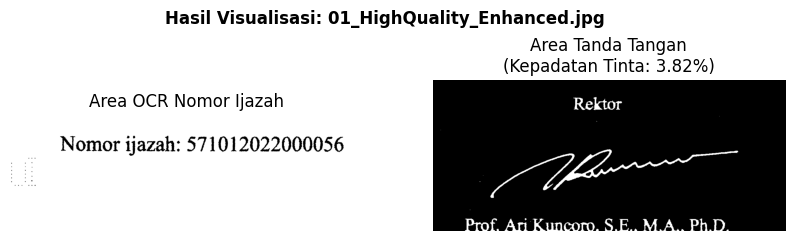

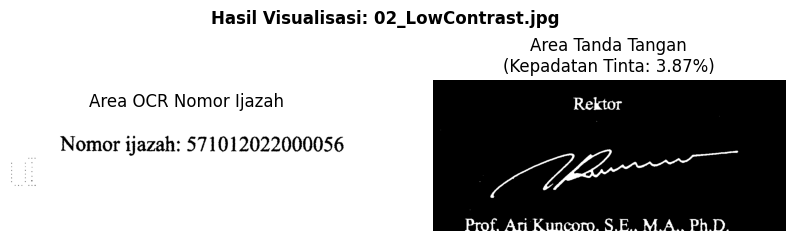

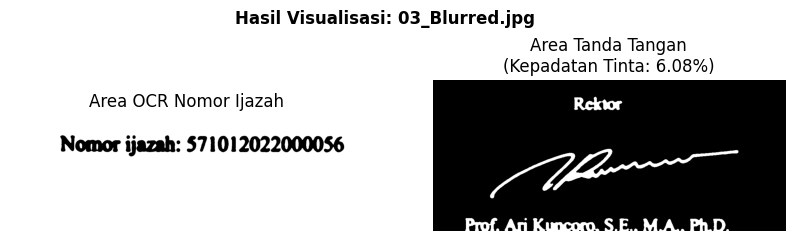

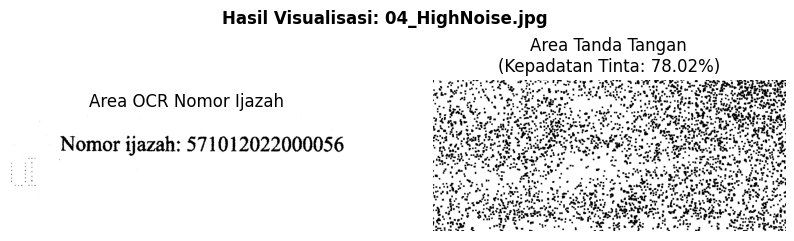

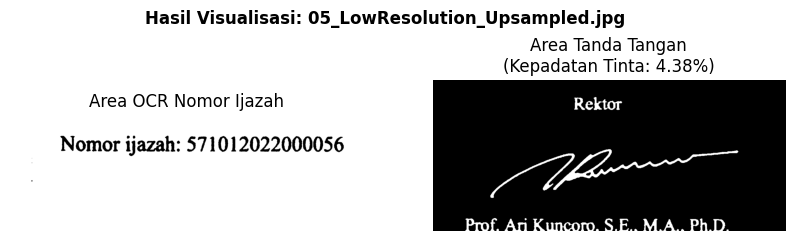

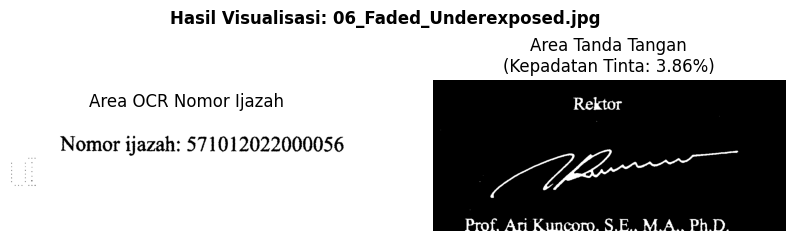

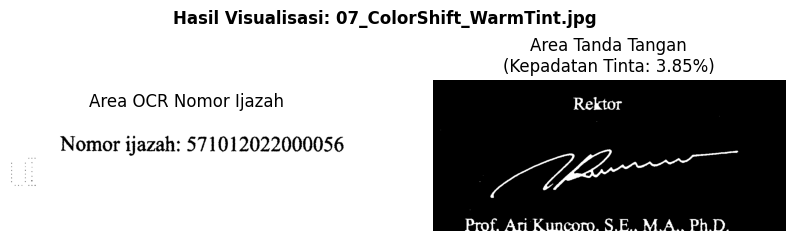

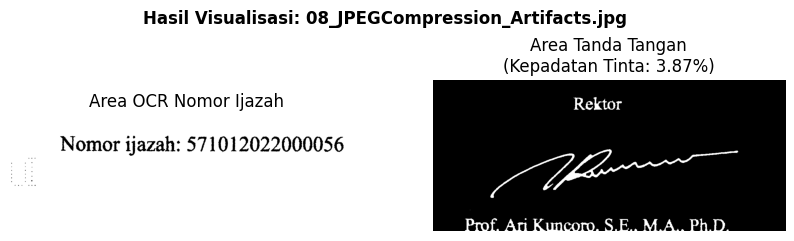

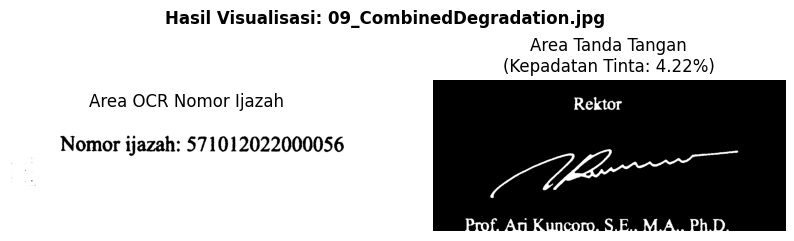

In [35]:
# SEL 8: VISUALISASI PERBANDINGAN

for filename, data in data_ijazah.items():
    if 'thresh_nomor' not in data or 'morph_ttd' not in data:
        continue

    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    fig.suptitle(f"Hasil Visualisasi: {filename}", fontsize=12, fontweight='bold')

    ax[0].imshow(data['thresh_nomor'], cmap='gray')
    ax[0].set_title('Area OCR Nomor Ijazah')
    ax[0].axis('off')

    ax[1].imshow(data['morph_ttd'], cmap='gray')
    ax[1].set_title(f"Area Tanda Tangan\n(Kepadatan Tinta: {data['ink_density']:.2f}%)")
    ax[1].axis('off')

    plt.show()
    print("\n")